<a href="https://colab.research.google.com/github/Rubal-code/DEEP-LEARNING/blob/main/02_pytorch_fundamentals_video_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
from sklearn.datasets import make_circles

# make 1000 samples
n_samples = 1000
# create circle
X, y = make_circles(n_samples=n_samples, noise=0.03, random_state=42)



In [9]:
len(X),len(y)

(1000, 1000)

In [10]:
X.size

2000

In [11]:
print("first 5 rows of X")
print(X[:5])
print("first 5 rows of y")
print(y[:5])

first 5 rows of X
[[ 0.75424625  0.23148074]
 [-0.75615888  0.15325888]
 [-0.81539193  0.17328203]
 [-0.39373073  0.69288277]
 [ 0.44220765 -0.89672343]]
first 5 rows of y
[1 1 1 1 0]


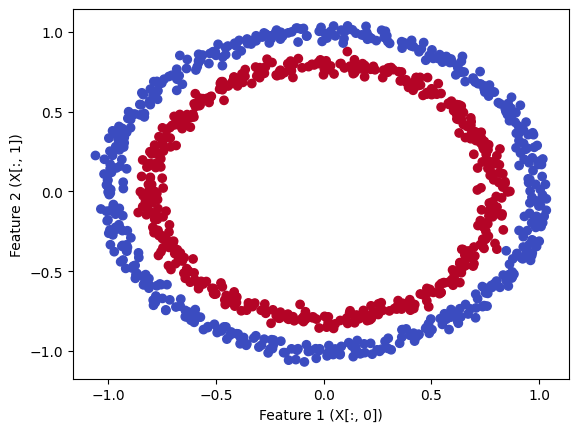

In [12]:
import matplotlib.pyplot as plt

plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm")
plt.xlabel("Feature 1 (X[:, 0])")
plt.ylabel("Feature 2 (X[:, 1])")
plt.show()

In [13]:
# make the dataframe of the circle data
import pandas as pd

circle = pd.DataFrame({"X1": X[:, 0], "X2": X[:, 1], "label": y})

# turn our data into tensors

In [14]:
import torch
torch.__version__

'2.14.1+cu130'

In [15]:
X.dtype

dtype('float64')

In [16]:
# turn data into tensors
X=torch.from_numpy(X).type(torch.float32)
y=torch.from_numpy(y).type(torch.float32)

In [17]:
type(X) , X.dtype , y.dtype

(torch.Tensor, torch.float32, torch.float32)

In [18]:
torch.manual_seed(42)

In [19]:
# 1 train test split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [20]:
len(X_train),len(X_test),len(y_train),len(y_test)

(800, 200, 800, 200)

# 2) lets build a model
* set up device agnostic code so our code will run on an accelerator (gpu) if there is one
* construct a model (`by subclassing nn.module`)
* define loss function and optimizer
* create a training and testing loop

In [21]:
import torch
from torch import nn

device = "cuda" if torch.cuda.is_available() else "cpu"
device


'cuda'

In [22]:
X_train

tensor([[ 0.6579, -0.4651],
        [ 0.6319, -0.7347],
        [-1.0086, -0.1240],
        ...,
        [ 0.0157, -1.0300],
        [ 1.0110,  0.1680],
        [ 0.5578, -0.5709]])

# we've set up device agnostic code, lets create a model :
* SubClass `nn.Module`
* create 2 `nn.Linear()`layers that are capable of handling the shape of the data
* defines a forward method that outlines the forward pass of the model
* Inititate an instance of our model class and send it to target device


In [23]:
X_train.shape

torch.Size([800, 2])

In [24]:
# construct a model
class CircleModelV0(nn.Module):
    def __init__(self):
        super().__init__()

        # create a 2 nn.linear layers
        self.layer1 = nn.Linear(in_features=2,out_features=5)
        self.layer2 = nn.Linear(in_features=5,out_features=1)

    # define forward method
    def forward(self,x):
        return self.layer2(self.layer1(x)) # x -> layer1 -> layer2 -> output
# instantiate an instance of our model class and send it to the target device
model_0 = CircleModelV0().to(device)
model_0

CircleModelV0(
  (layer1): Linear(in_features=2, out_features=5, bias=True)
  (layer2): Linear(in_features=5, out_features=1, bias=True)
)

In [25]:
# lets replicate the upper model here using the nn.Seqeuntial()
model_1 = nn.Sequential(
    nn.Linear(in_features=2,out_features=5),
    nn.Linear(in_features=5,out_features=1)
).to(device)
model_1

Sequential(
  (0): Linear(in_features=2, out_features=5, bias=True)
  (1): Linear(in_features=5, out_features=1, bias=True)
)

In [26]:
model_1.state_dict()

OrderedDict([('0.weight',
              tensor([[-0.0829, -0.2872],
                      [ 0.4691, -0.5582],
                      [-0.3260, -0.1997],
                      [-0.4252,  0.0667],
                      [-0.6984,  0.6386]], device='cuda:0')),
             ('0.bias',
              tensor([-0.6007,  0.5459,  0.1177, -0.2296,  0.4370], device='cuda:0')),
             ('1.weight',
              tensor([[ 0.0697,  0.3613,  0.0489, -0.1410,  0.1202]], device='cuda:0')),
             ('1.bias', tensor([-0.1213], device='cuda:0'))])

In [27]:
# predictions
with torch.inference_mode():
    untrained_preds = model_1(X_test.to(device))
    pred = torch.round(untrained_preds[:10])
    print(pred == y_test[:10].to(device))

tensor([[False,  True, False,  True, False, False,  True,  True, False,  True],
        [False,  True, False,  True, False, False,  True,  True, False,  True],
        [False,  True, False,  True, False, False,  True,  True, False,  True],
        [False,  True, False,  True, False, False,  True,  True, False,  True],
        [False,  True, False,  True, False, False,  True,  True, False,  True],
        [False,  True, False,  True, False, False,  True,  True, False,  True],
        [False,  True, False,  True, False, False,  True,  True, False,  True],
        [False,  True, False,  True, False, False,  True,  True, False,  True],
        [False,  True, False,  True, False, False,  True,  True, False,  True],
        [False,  True, False,  True, False, False,  True,  True, False,  True]],
       device='cuda:0')


In [29]:
# set up the loss function
# loss_function  = nn.BCELoss = requires inputs to have gone through the sigmoid activation function prior to input to bceloss
loss_fn = nn.BCEWithLogitsLoss() # bcewithlogitloss = sigmoid activation function built-in


# optimizer
optimizer = torch.optim.SGD(params=model_1.parameters(),lr=0.1)

In [37]:
# calculate accuracy  = out of 100 examples , what percentage does our model get right
def accuracy_fn(y_true,y_pred):
    correct = torch.eq(y_true,y_pred).sum().item()
    acc = (correct/len(y_pred))*100
    return acc

# train a model
steps:
1) forward pass
2) calculate loss
3) optimizer zero grad
4) loss backward
5) optimizer step

# 3.1 going from the raw logit -> prediction probabilities -> prediction labels
our model are going to be the raw logits
we can convert these logits into prediction probabilities by passing them to the some kind of the activation function (eg:sigmoid for classifiction and softmax for the multiclass classification)
then by rounding them we get the prediction labels

In [41]:
# view the first 5 outputs of the forward pass on test data
model_0.eval()
with torch.inference_mode():
  y_logits = model_1(X_test.to(device))
  y_pred = torch.round(torch.sigmoid(y_logits))
  print(y_logits[:5])
  print(y_pred[:5])

tensor([[-0.0338],
        [-0.0309],
        [ 0.0894],
        [-0.0692],
        [ 0.2967]], device='cuda:0')
tensor([[0.],
        [0.],
        [1.],
        [0.],
        [1.]], device='cuda:0')


In [44]:
torch.sigmoid(y_logits)[:5]

tensor([[0.4916],
        [0.4923],
        [0.5223],
        [0.4827],
        [0.5736]], device='cuda:0')

In [47]:
torch.round(torch.sigmoid(y_logits)[:5])

tensor([[0.],
        [0.],
        [1.],
        [0.],
        [1.]], device='cuda:0')

In [48]:
y_test[:5]

tensor([1., 0., 1., 0., 1.])